### **Name: Donovan Neal**

## Technical Setup

In [62]:
#Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Format for every chart in the notebook
sns.set_theme(style="whitegrid")
sns.set_palette(["#E50914", "#221F1F", "#B81D24"])
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "axes.edgecolor": "gray",
    "axes.linewidth": 0.8,
    "font.size": 12,
    "axes.titleweight": "bold"
})

## Part 1: Data Inspection & Descriptive Statistics

In [46]:
#Load and view dataset
df = pd.read_csv('netflix_titles.csv')
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,25-Sep-21,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,24-Sep-21,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,24-Sep-21,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,20-Nov-19,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,1-Jul-19,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,1-Nov-19,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,11-Jan-20,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [18]:
#Display information on dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.8 MB


In [49]:
#Calculate central tendency and spread for numerical fields in dataset
numeric_summary = (
    df["release_year"].agg(["count", "mean", "std", "min", "max"])
     .round(2).to_frame("release_year").T)
numeric_summary

,count,mean,std,min,max
release_year,8807.0,2014.18,8.82,1925.0,2021.0


In [50]:
#Generate summary statistics for categorical fields in dataset
category_summary = (
    df.select_dtypes(exclude="number").describe().T
     .rename(columns={"top": "most_frequent",
                      "freq": "frequency"}))
category_summary

,count,unique,most_frequent,frequency
show_id,8807,8807,s1,1
type,8807,2,Movie,6131
title,8807,8804,15-Aug,2
director,6173,4528,Rajiv Chilaka,19
cast,7982,7692,David Attenborough,19
country,7976,748,United States,2818
date_added,8797,1767,1-Jan-20,109
rating,8803,17,TV-MA,3207
duration,8804,220,1 Season,1793
listed_in,8807,514,"Dramas, International Movies",362


### Dataset Summary

This dataset contains 8807 titles across 12 columns, consisting of primarily movies (6131), with TV shows making up the rest of the titles (2676), spanning from the years of 1925 to 2021. Given the median of `release_year` being 2017, the large majority of titles in this dataset
are heavily skewed towards modern titles, mostly between the years of 2017 - 2019.

## Part 2: Data Quality Audit & Light Cleaning

In [66]:
#Check for missing values
missing_data = df.isnull().sum().to_frame("null_count")
missing_data

,null_count
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,0


In [34]:
#Check for duplicate rows
df.duplicated().sum()

np.int64(0)

While analyzing the DataFrame, we discover that there are missing values, values placed in incorrect collumns, 
values leading with whitespace and incorrect characters, and broken text in multiple columns.

To handle columns that contained missing values, I used `.fillna()` to fill in missing values with `"Unknown"`
as opposed to keeping the value in that row blank. To deal with values that were placed in the incorrect column, I used `.loc` to shift the misplaced values in the `rating` column to the `duration` column. 
To handle values that were led with incorrect values, I used `.str.strip()` to strip the values across all columns that had values that lead with whitespace or commas. Finally, to handle broken text in collumns, I used the regex `r'[^a-zA-Z0-9\s:\-–&\'!?.,]` to filter out values in columns that contained symbols that should not be present in that column, so things such as an exclamation mark in the `director` column. 

In [23]:
#Fill in missing values with "Unknown"
df_fill = df.fillna({
    "director": "Unknown", 
    "cast": "Unknown", 
    "country": "Unknown", 
    "date_added": "Unknown", 
    "rating": "Unknown", 
    "duration": "Unknown"
})

In [24]:
#Replaces broken text in columns
for col in df.select_dtypes(exclude="number"):
    df[col] = df[col].str.replace(r'[^a-zA-Z0-9\s:\-–&\'!?.,]', '', regex=True)

In [56]:
#Strips leading commas and whitespace in the dataset
for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].str.strip(', ')

In [60]:
#Formats `date_added` column to datetime from text
df["date_added"] = pd.to_datetime(df["date_added"])

In [57]:
#Finds the values in `rating` that belong in `duration` column
mask = df["rating"].str.contains(r'^\d+', na=False)

#Shifts the incorrect values in `rating` to `duration` column
df.loc[mask, "duration"] = df.loc[mask, "rating"]

#Replaces incorrect values in `rating` with "Unknown"
df["rating"] = df["rating"].replace(r'^\d+.*', "Unknown", regex=True)

## Part 3: Data Exploration and Visualizations

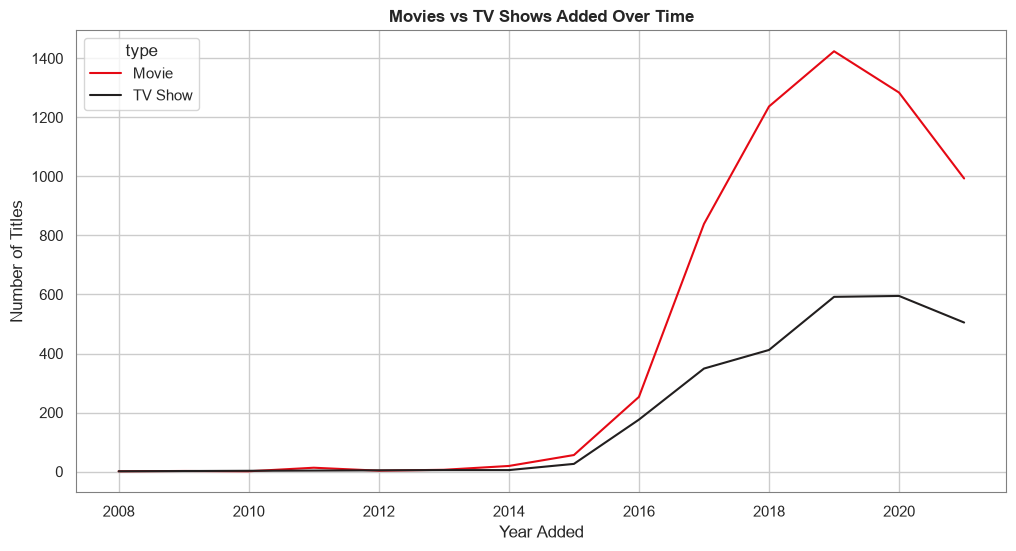

In [38]:
df['year_added'] = df['date_added'].dt.year

counts = df.groupby(['year_added', 'type']).size().reset_index(name='count')

sns.lineplot(data=counts, x='year_added', y='count', hue='type')
plt.title('Movies vs TV Shows Added Over Time')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.show()


From the chart, we can see that from 2008 to 2014, the movies and TV shows added to Netflix were fairly even until around 2015
when the amount of movies added to Netflix far outweighted the number of TV shows being added. Also, we can see the amount of
titles being added to Netflix rapidly grew beginning in 2015 and started to decrease for the first time beginning during 2019. 

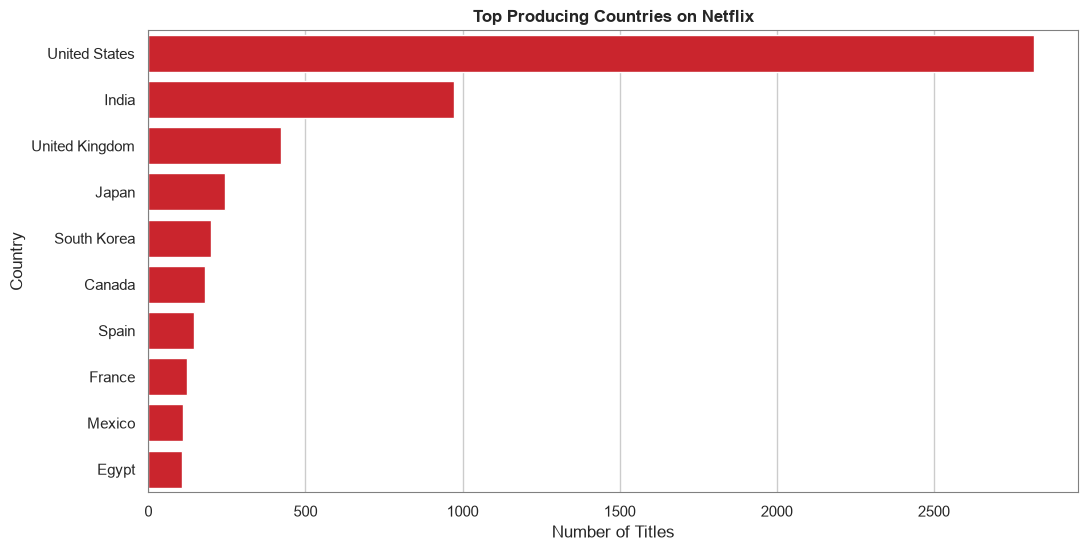

In [39]:
country_counts = df["country"].value_counts().head(10).reset_index()
country_counts.columns = ["country","count"]

sns.barplot(data=country_counts, x="count", y="country")
plt.title("Top Producing Countries on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

From the chart, we can see that the United States is by far the top producing country when it comes to titles
available on Netflix. Aside from that, we can that Mexico, France, Spain, Canada, South Korea, and Japan have the fewest 
amount of titles on Netflix. From this data, we can infer that titles produced in the United States tend to perform the best on Netflix. 

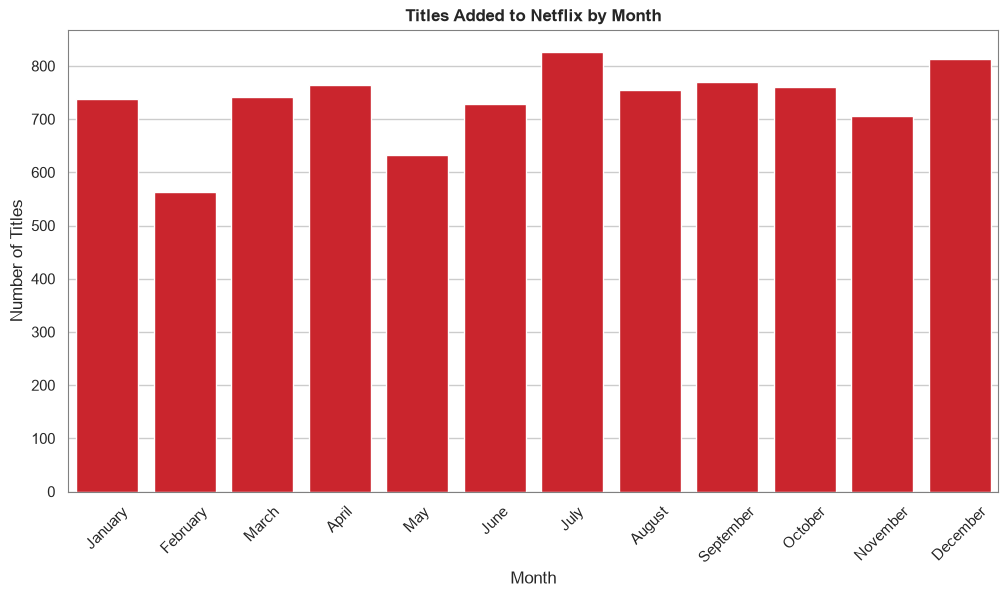

In [61]:
df['month_added'] = df["date_added"].dt.month_name()

month_counts = df['month_added'].value_counts().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December']
).reset_index()
month_counts.columns = ['month', 'count']

sns.barplot(data=month_counts, x='month', y='count')
plt.xticks(rotation=45)
plt.title('Titles Added to Netflix by Month')
plt.xlabel('Month')
plt.ylabel('Number of Titles')
plt.show()

Judging from the graph, there doesn't appear to be much difference in number of titles added on which months, but 
July and December are the months that have titles added more frequently, while Februrary and June are the months that recieve
the least frequent titles added.

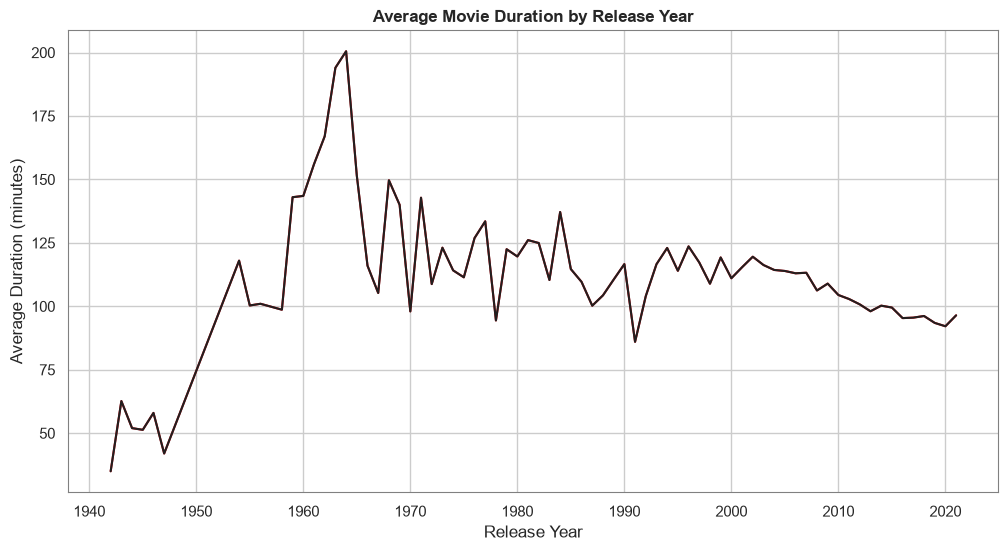

In [63]:
movies = df[df['type'] == 'Movie'].copy()

movies['duration_min'] = movies['duration'].str.extract('(\d+)').astype(float)

avg_duration = movies.groupby('release_year')['duration_min'].mean()

sns.lineplot(x=avg_duration.index, y=avg_duration.values)

sns.lineplot(x=avg_duration.index, y=avg_duration.values)
plt.title('Average Movie Duration by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Duration (minutes)')
plt.show()

From the chart, we can see that over the decades, the trend of movie durations has varied greatly. From 1940 to 1950, 
movies tended to be less 70 minutes but then between 1950 and 1960, movies then grew in average duration sitting at around 110 minutes on average, and then from 1960 to 1970 movies began to peak on average to upwards of 200 minutes, but then from 1970 onwards began steadily decling in duration 
sitting anywhere 90 minutes to 130 minutes on average. From this data, we can infer that consumers prefered movies that ranged from 90 to 130 minutes as opposed to the shorter movies in the 40's and 50's and the longer movies in 70's. 

## Part 4: Modeling Recommendations and Data Pitfalls

One machine learning task that I would propose to the Netflix leadership based on this data would be whether newer or older movies drive more engagemnt on Netflix. This is a classification problem as we are looking to classify movies based on engagement. The variable we are trying to predict is consumer engagment with a movie after it has been recently added to Netflix. Features from the dataset that we would include in the model would be `date_added` and `release_year` especially, and then all information related to the movie so the duration and titles for example. 

Based on my exploratory data analysis, the first specific data challenge in this dataset that would complicate modeling would be the large amounts of missing data in the dataset. In order to remedy that, you would have to first figure out why the data is missing in the first place and whether it missing for valid reasons such as it not being applicable or the information not being provided, or whether the data genuinely is missing for some unknown reason. Then decide whether to drop or fill those rows with another value so it can be used for modeling. The second data challenge in the dataset is that there is a lot of broken text across the entire dataset. There are many places where there are values containg unusual symbols and text where there should not be. To fix this, you should find those values with the text and replace the ones containing this broken text so the information is able to be properly used for modeling. 

- Based on the top producing countries in Netflix, Netflix heavily favors certian markets, especially the United States when it comes to what titles get added to their platform
- Based on the Movies vs. TV shows added over time, users on Netflix seem to prefer watching more movies over TV shows based on how much more movies added to Netflix as opposed to TV shows
- Factors such as the genre, country, and duration are critical when it comes to figuring out what kind of content perfroms best on Netflix, whether it's shows or movies that have shorter durations, content that comes from a certain genre, and content that was released in a certain tome frame as examples